# MOSS: qualification before comparing map algorithms
## tl;dr
All four configurations failed their predeclared gates. **No algorithm ranking was produced.** We obtained 88 diagnostic answers. The original 733-task comparison stopped after 19 controls; later pilots retained those failures. Single-track descriptions were more stable than direct comparison but changed one instrument label in one of six identical repeats.

## Context & Methods
Five frozen candidates: k-means 25% audio, average linkage 75%, directional mean-shift 75%, compact mean-shift 50%, selected k-means 60%. This notebook evaluates the **judge**, not the candidates.

### Key Assumptions
Control truth is limited to byte identity and digital silence. Different-song similarity has no human ground-truth score. Fractions below use different controls and are not comparable model accuracy estimates. Instruct's `secondMusic` alias is normalized only for functional diagnostics; its original schema failure remains recorded. Thinking's syntax normalization was specified before inference.

Runtime and checkpoints are pinned in README.md. Raw replies and audio remain private. All evidence needed for the following aggregates is in control-observations.json.

## Data
### Load anonymous observations

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analyze_controls import analyze
root = Path.cwd()
observations = json.loads((root / 'control-observations.json').read_text())
results = analyze(observations)
assert results == json.loads((root / 'results-2026-10-14.json').read_text())
assert len(observations) == 88
assert not any(x['truncated'] for x in observations)
assert not any(x['qualified'] for x in results.values())
plt.rcParams.update({'font.size': 11, 'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'{len(observations)} answers; no truncated responses; all gates failed.')

88 answers; no truncated responses; all gates failed.


## Results
### Qualification outcomes

In [2]:
table = pd.DataFrame([{
    'Configuration': key,
    'Answers': value['answered'],
    'Schema usable': value['usable_schema'],
    'Functional hard controls': f"{value['functional_control_passes']}/{value['functional_control_total']}",
    'Qualified': value['qualified']
} for key, value in results.items()])
display(table)

,Configuration,Answers,Schema usable,Functional hard controls,Qualified
0,instruct-multi,19,19,13/19,False
1,instruct-pair,27,0,9/21,False
2,thinking-pair,27,27,15/21,False
3,thinking-attributes,15,15,14/15,False


The 27-answer pair pilots contain 21 hard identity/silence controls plus three musical pairs in both orders. The 9/21 Instruct fraction is a diagnostic result after key normalization, not a passed schema. Thinking recognized all identical pairs and leading silence but hallucinated music in every trailing-silence test.

### The same musical pairs in opposite order

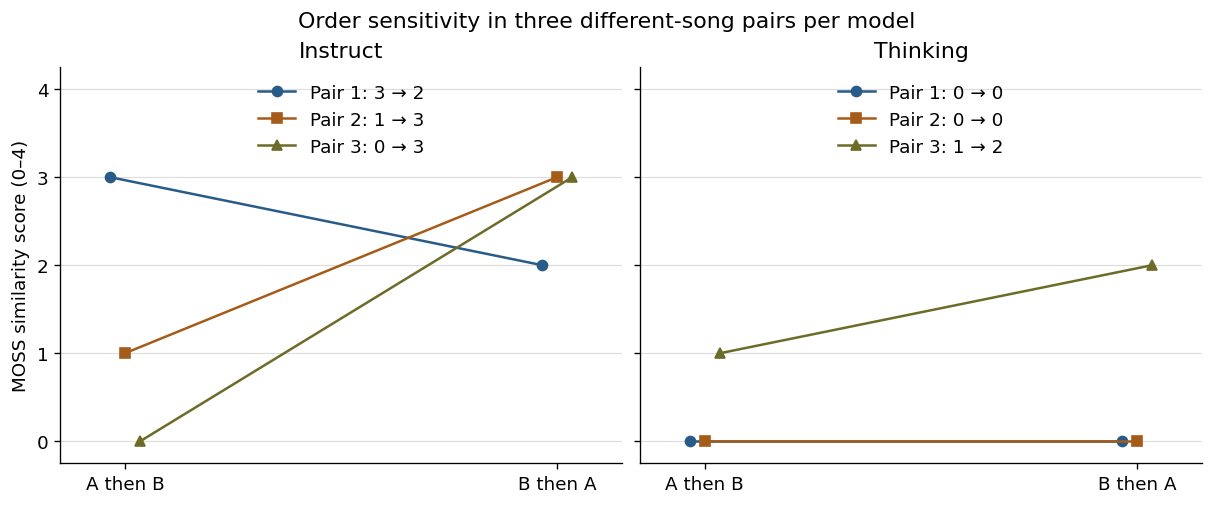

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.1), sharey=True, constrained_layout=True)
lookup = {x['task_id']: x for x in observations}
colors = ['#285c88', '#a55c19', '#6d6b28']
for ax, experiment, title in zip(axes, ['instruct-pair', 'thinking-pair'], ['Instruct', 'Thinking']):
    pairs = [x for x in observations if x['experiment'] == experiment and x['role'] == 'reverse']
    for index, item in enumerate(pairs):
        a = lookup[item['original']]['answer']['similarity']; b = item['answer']['similarity']
        # Horizontal offsets distinguish pairs with equal values; each remains in its labelled order.
        offset = (index - 1) * 0.035
        ax.plot(np.array([0, 1]) + offset, [a, b], marker=['o', 's', '^'][index], color=colors[index], label=f'Pair {index + 1}: {a} → {b}')
    ax.set_title(title); ax.set_xticks([0, 1], ['A then B', 'B then A']); ax.set_xlim(-.15, 1.15)
    ax.set_ylim(-.25, 4.25); ax.set_yticks(range(5)); ax.grid(axis='y', color='#dddddd', linewidth=.7); ax.legend(loc='upper center', frameon=False)
axes[0].set_ylabel('MOSS similarity score (0–4)')
fig.suptitle('Order sensitivity in three different-song pairs per model')
fig.savefig(root / 'order-sensitivity.png', dpi=160, bbox_inches='tight')
plt.show()

Instruct changed scores by 1, 2 and 3 points (mean absolute difference 2). Thinking changed them by 0, 0 and 1 (mean 0.33). Tracks differ between pilots; this is not a paired model benchmark. Passing this small order check does not repair Thinking's separate trailing-silence failures.

### Single-recording annotation repeatability

In [4]:
attribute_rows = [x for x in observations if x['experiment'] == 'thinking-attributes']
changes = []
for item in attribute_rows:
    if item['role'] != 'control_duplicate':
        continue
    original = lookup[item['original']]['answer']
    diff = {key: [original[key], item['answer'][key]] for key in original if original[key] != item['answer'][key]}
    if diff:
        changes.append(diff)
assert len(changes) == 1
print(json.dumps(changes, indent=2))

[
  {
    "instruments": [
      [
        "bass",
        "electric_guitar",
        "electronic_drums"
      ],
      [
        "bass",
        "drum_kit",
        "electric_guitar"
      ]
    ]
  }
]


## Takeaways
- The 88 answers support a failed judge-qualification result, not an algorithm winner.
- The single-recording pilot correctly detected music and silence. One instrument change in six identical repeats is a narrow repeatability issue; its practical impact needs a separate noise-tolerant validation and human-labelled features.
- The installed average-linkage 75/25 candidate remains based on earlier geometry/coverage analysis, without new MOSS validation.
- Prepared audio and allocation data remain local for reuse; the temporary A40 pod was deleted and a subsequent read returned 404.

Validation: this notebook is executed top-to-bottom, reconciles saved aggregates with all 88 identity-free observations, and retains its tables and figure.